## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?**

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sadat Hassan

**Date:** 10/14/2026

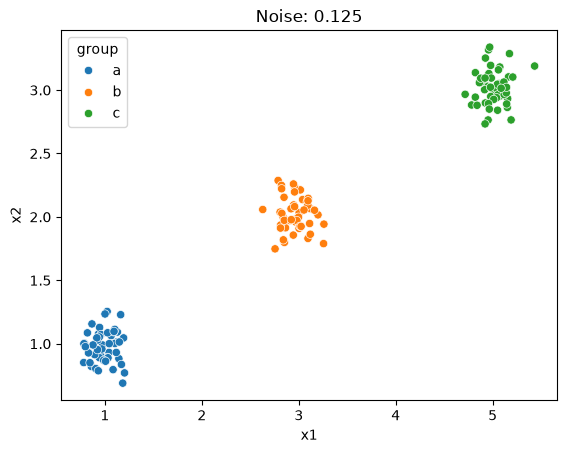

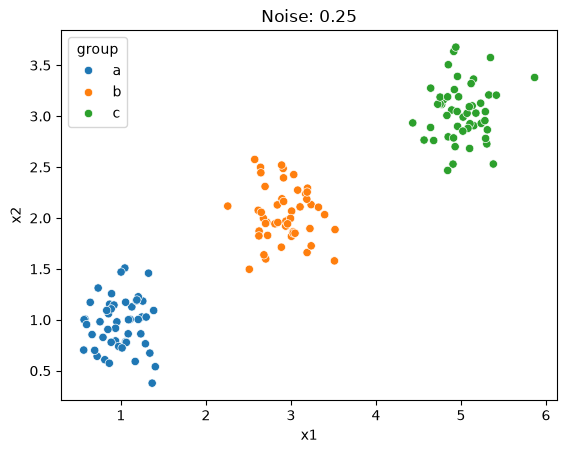

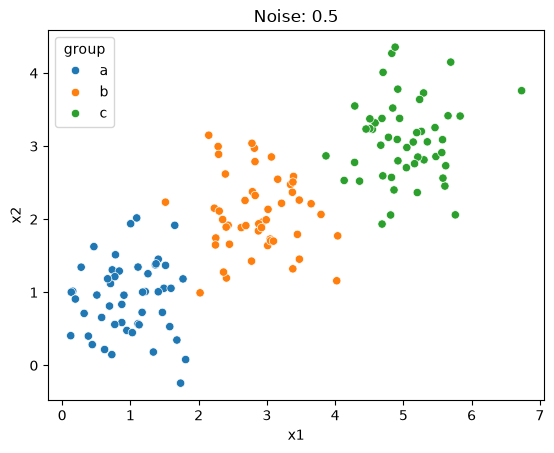

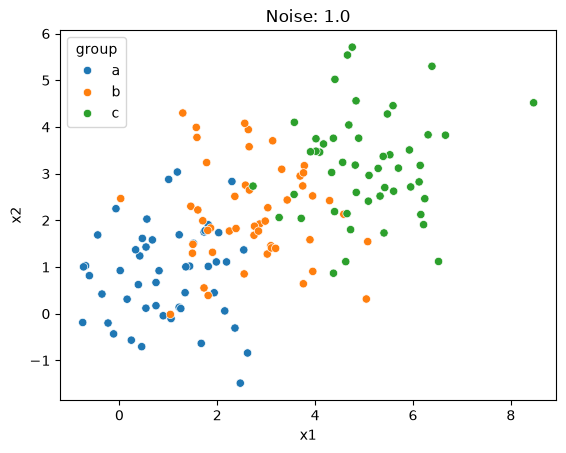

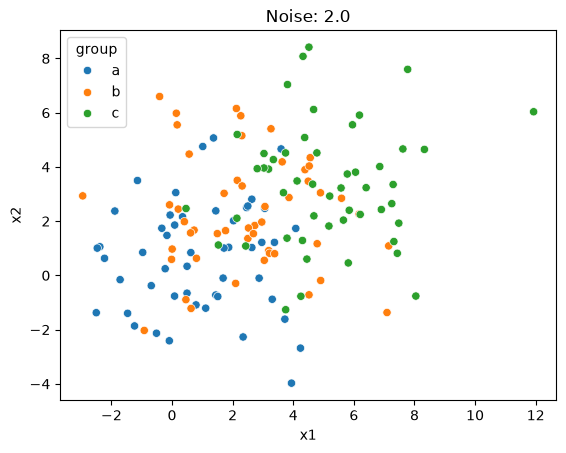

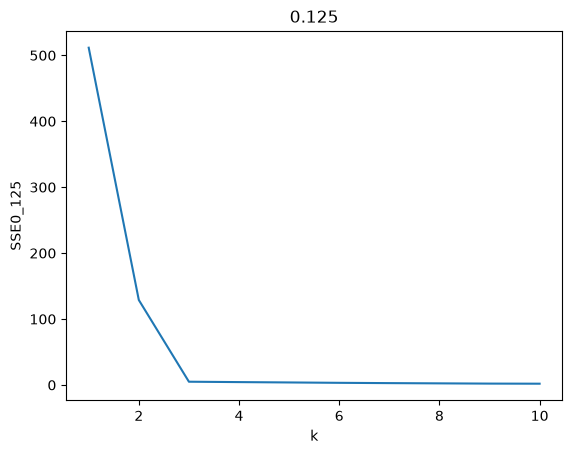

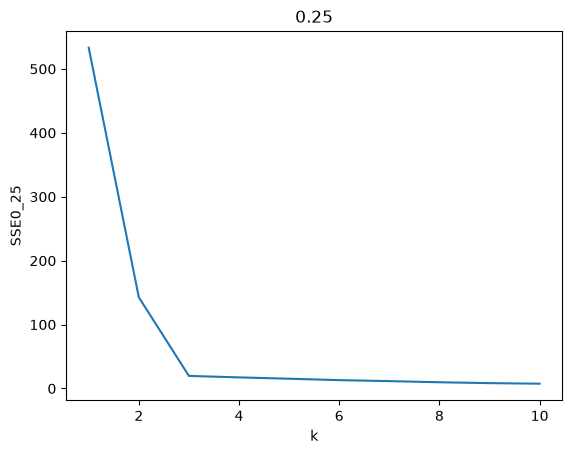

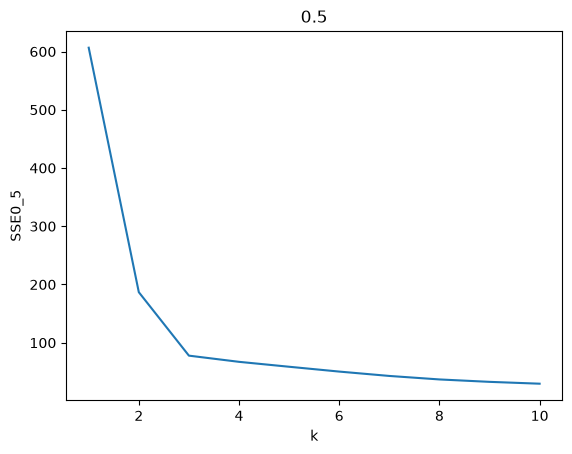

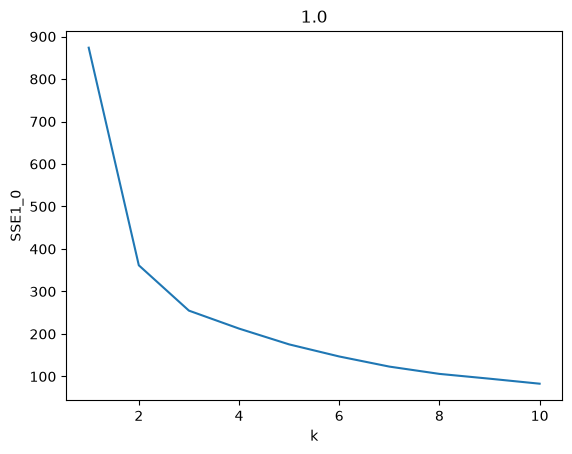

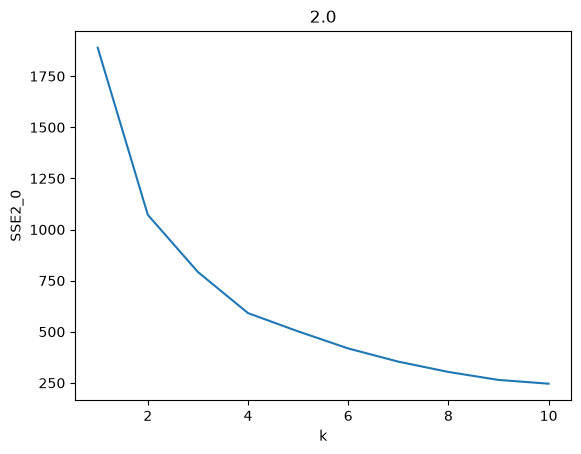

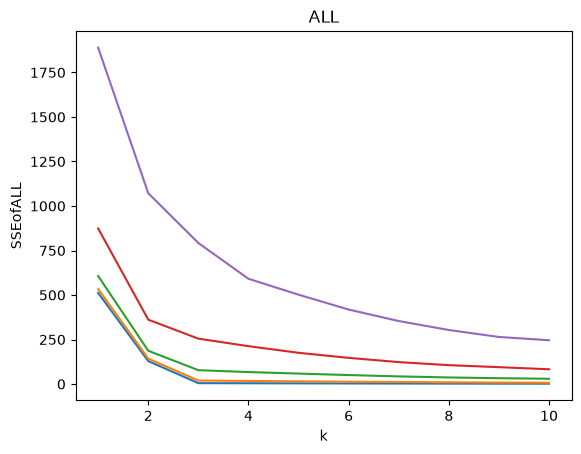

In [23]:
# Your Phase 1 solution to the problem goes here.
#######################################################################
# Question 1
# Part 1, copy and run
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#Q1 Part 2
sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group").set(title ='Noise: 0.125')
plt.show()
sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group").set(title ='Noise: 0.25')
plt.show()
sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group").set(title ='Noise: 0.5')
plt.show()
sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group").set(title ='Noise: 1.0')
plt.show()
sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group").set(title ='Noise: 2.0')
plt.show()

#As the noise increases, the groups become more and more mixed and intertwined. For example, the noise levels of 0.125 and 0.25 are well separated,
#but then 0.5 starts to overlap a bit, leading to 1.0 and 2.0 noise mixing a lot. This suggests that with more noise, comes more varied responses.

#Q1 Part 3
ks = np.arange(1, 11)
SSE0_125 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_125[['x1','x2']]).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE0_125).set(title="0.125", xlabel="k", ylabel="SSE0_125")
plt.show()
SSE0_25 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_25[['x1','x2']]).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE0_25).set(title="0.25", xlabel="k", ylabel="SSE0_25")
plt.show()
SSE0_5 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df0_5[['x1','x2']]).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE0_5).set(title="0.5", xlabel="k", ylabel="SSE0_5")
plt.show()
SSE1_0 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df1_0[['x1','x2']]).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE1_0).set(title="1.0", xlabel="k", ylabel="SSE1_0")
plt.show()
SSE2_0 = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(df2_0[['x1','x2']]).inertia_ for k in ks]
sns.lineplot(x=ks, y=SSE2_0).set(title="2.0", xlabel="k", ylabel="SSE2_0")
plt.show()

sns.lineplot(x=ks, y=SSE0_125).set(title="0.125", xlabel="k", ylabel="SSE0_125")
sns.lineplot(x=ks, y=SSE0_25).set(title="0.25", xlabel="k", ylabel="SSE0_25")
sns.lineplot(x=ks, y=SSE0_5).set(title="0.5", xlabel="k", ylabel="SSE0_5")
sns.lineplot(x=ks, y=SSE1_0).set(title="1.0", xlabel="k", ylabel="SSE1_0")
sns.lineplot(x=ks, y=SSE2_0).set(title="ALL", xlabel="k", ylabel="SSEofALL")
plt.show()

#The elbow smooths out as the noise increases. With minimal noise, an evident elbow is present
#as showcased in the graphs with 0.125 and 0.25 noise. The curve keeps smoothing out as 0.5, 1.0,
#and 2.0 noise is accounted for. Due to the apparent elbow, k can be chosen as 3 for the lower
#noise levels; however, it is more tricky to decipher the k for the higher noise levels as the 
#elbow is less apparent. The graph smooths out so it could be more like 3, 4, or 5.

#Q1 Part 4
#The elbow is where adding more clusters is not as beneficial or useful. In our numerical
#simulations, it is shown that the elbow lies around k = 3. This is evident towards the lower 
#noise levels, but can be harder to spot for the higher noise levels. The reason for this is that
#the groups overlap in high noise, which allows the clusters to be more effective than if the groups
#were spread out from the start.

(148, 7)
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
             index    Year  Spending (2020 USD)  Percent of GDP  \
count   148.000000   148.0           148.000000      148.000000   
mean   2831.256757  2020.0         13153.747670        0.019619   
std    1654.299355     0.0         68005.236120        0.015033   
min      32.000000  2020.0             8.622460        0.000054   
25%    1409.000000  2020.0           204.877177        0.010413   
50%    2871.000000  2020.0           959.535443        0.015324   
75%    4222.500000  2020.0          5289.998320        0.024327   
max    5880.000000  2020.0        778397.200000        0.098470   

       Percent of Government Spending  Spending per Capita  
count             

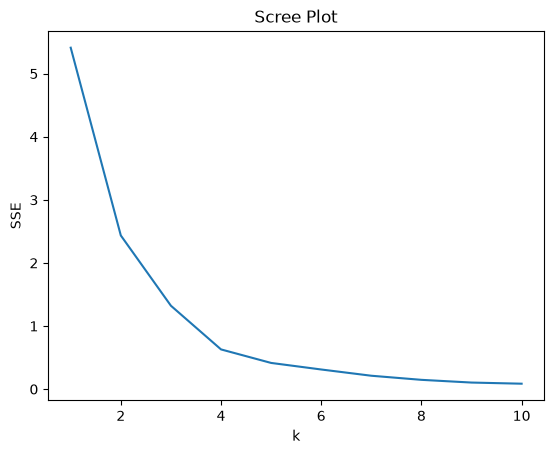

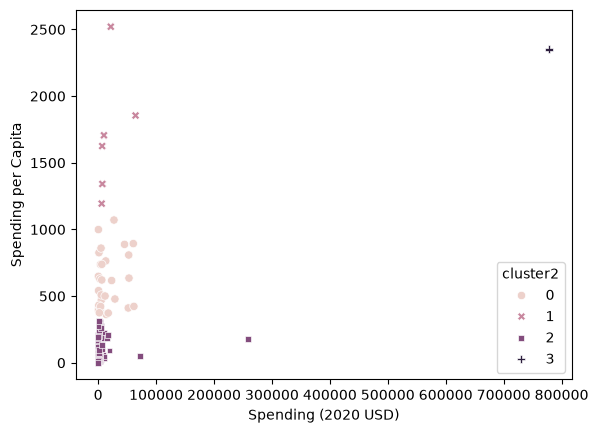

cluster2
0    [Australia, Austria, Bahrain, Belgium, Brunei,...
1    [Israel, Kuwait, Norway, Oman, Saudi Arabia, S...
2    [Afghanistan, Albania, Algeria, Angola, Argent...
3                           [United States of America]
Name: Country, dtype: object
                       Country  cluster2
5540  United States of America         3


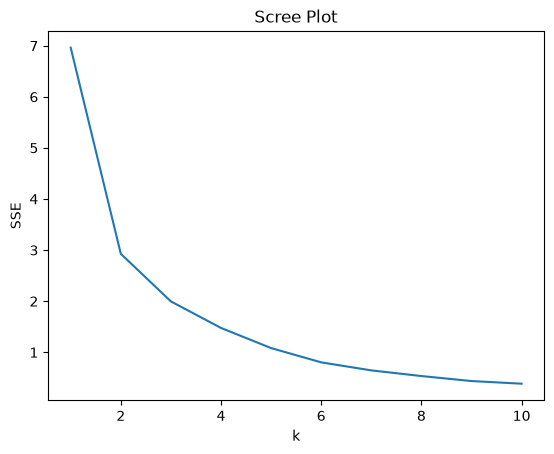

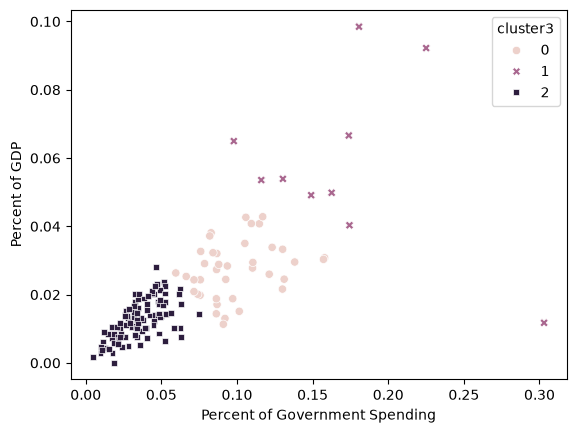

cluster3
0    [Bahrain, Bangladesh, Botswana, Brunei, Burkin...
1    [Algeria, Armenia, Azerbaijan, Belarus, Israel...
2    [Afghanistan, Albania, Angola, Argentina, Aust...
Name: Country, dtype: object
                       Country  cluster3
5540  United States of America         0


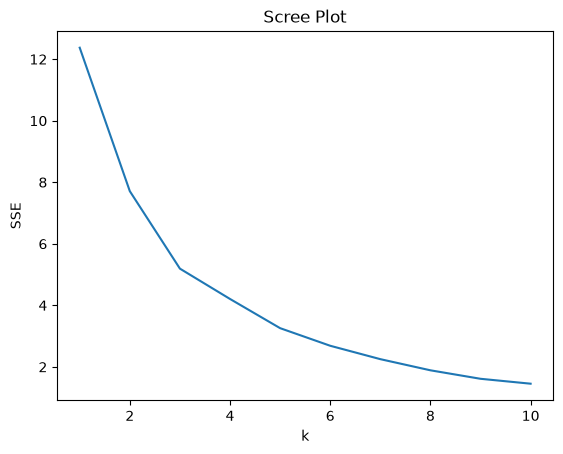

cluster4
0    [Afghanistan, Albania, Angola, Argentina, Aust...
1    [Algeria, Armenia, Azerbaijan, Bahrain, Belaru...
2    [Israel, Kuwait, Oman, Saudi Arabia, Singapore...
Name: Country, dtype: object
                       Country  cluster4
5540  United States of America         2


In [24]:
#################QUESTION 2

##################QUESTION 2 PART 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df = df.loc[df["Year"] == 2020].dropna().copy()
print(df.shape)
print(df.dtypes)
print(df.describe())

#NO further cleaning neeeded. After verifying and reviewing the types and describe of df, it is 
#shown that everything aligns as it should. Additionally, 148 countries were found just like
#the question suggests should be the case.

############### QUESTION 2 PART 2
features = ["Spending (2020 USD)", "Spending per Capita"] #max min
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE") #plot scree
plt.show()
#fit with k = 4
model = KMeans(n_clusters=4, n_init=10,random_state=0).fit(X)
df["cluster2"] = model.labels_
sns.scatterplot( data = df, x = "Spending (2020 USD)", y = "Spending per Capita", hue = "cluster2", style = "cluster2")
plt.show()

print(df.groupby("cluster2")["Country"].apply(list))
print(df.loc[df["Country"].str.contains("United States"), ["Country", "cluster2"]])

#I see that the scree plot has an apparent elbow at k=4, so k = 4 was used for the n_clusters
#The united states is in its own third cluster due to their large spending being higher than other countries
#The other clusters have the pattern of being separated by their spending per capita. 
#Cluster 1 has a high spending and cluster 2 has a low spending.

#########################QUESTION 2 Part 3

features = ["Percent of Government Spending", "Percent of GDP"] #max min
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE") #plot scree
plt.show()
# k =3
model = KMeans(n_clusters=3, n_init=10,random_state=0).fit(X)
df["cluster3"] = model.labels_
sns.scatterplot( data = df, x = "Percent of Government Spending", y = "Percent of GDP", hue = "cluster3", style = "cluster3")
plt.show()

print(df.groupby("cluster3")["Country"].apply(list))
print(df.loc[df["Country"].str.contains("United States"), ["Country", "cluster3"]])

# Compared to part 2, the elbow is now at k =3, so that was adjusted. The change with this is that the percent of government spending
# was compared to the percent of GDP, so its not about how big the spending is, but rather how much percentage wise is being spent
#this is a more comparable factor, that led teh United States to be in cluster 0 instead of in a whole different cluster
#by itself. There are only 3 clusters (0,1,2) in this one and not four like in part 2

####################Question 2 Part 4

features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot", xlabel="k", ylabel="SSE") #plot scree
plt.show()

#K = 3 
model = KMeans(n_clusters=3, n_init=10,random_state=0).fit(X)
df["cluster4"] = model.labels_

print(df.groupby("cluster4")["Country"].apply(list))
print(df.loc[df["Country"].str.contains("United States"), ["Country", "cluster4"]])

# Unlike part 2 and similarly to part 3, the United States is in a cluster with other countries.
# THis time, the United States is in cluster 2. Additionally, part 4 has a k=3, similar to part 3, and
#different from part 2's k=4. There were different priorities for parts 2-4, so that is why the countries
#in the clusters change. Spending wise, the United States spends a LOT on their military, especially since their GDP is very high.
#This was most likely the reasoning behind why it was in a cluster of its own in part 2, and then became in clusters with
# other countries as it got more comparative to its own stats. Going off money spent alone, the United States spends way more, but
#comparatively to its own total GDP is a different statistic. These patterns are easier to see when there are 2-variables. 
#Also, it was easier to find the k value for parts 2, then 3, and finding the k value for 4 was harder as the curve was smoother.

####################Question 2 Part 5
#The K-MC Algorithm did find some useful patterns for me in analyzing the spending when it was used more analytically.
#From part 2, it was evident that the United States was represented much differently as it was in a cluster of its own and 
#separated from the other countries. THat is why it was very important to look at Part 3's analysis which compared the total
#spending of a country to its total GDP. This put things in more comparable and fair statistics as it balances the fact that
#the United States has a much greater total GDP than other countries. However, there were some limitations that existed as with the scree plots.
#The scree plot had a more distinct elbow in part 2, but when we got to part 4 with 4 variables, the elbow was harder to find.
#Overall, teh K-MC Algorithm is very helpful in allowing us to understand patterns within the data given, especially when comparing one country to another.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]